# 3. Two-stage detector: Faster R-CNN
## How it works
Faster R-CNN finds objects in **two steps**:
1. **Region Proposal Network (RPN).** It looks at the whole image and makes many proposals: "maybe there is an object here". Proposals start from **anchors**. Anchors are boxes of fixed sizes and shapes on every position.
2. **Second stage.** It takes every proposal, looks at it closer and says the class. It also makes the box more exact.

The model has a **backbone** (ResNet-50, finds features), a **neck** (FPN, mixes small and big details) and the two heads above. We start from weights that were trained on COCO.

## Experiments
* **baseline**: default settings
* **small anchors**: our objects are small (notebook 01), so we make the anchors smaller
* **more proposals**: the RPN gives more proposals to the second stage

## Imports and paths
Libraries and the folders for the data, the training files and the figures.

In [1]:
import os
import io
import json
import time
import random
import contextlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image, ImageDraw
import torch

In [2]:
if os.path.exists("/kaggle/input"):
    import glob
    DATA = os.path.dirname(glob.glob("/kaggle/input/**/test_images.csv", recursive=True)[0])
    WORK = "/kaggle/working/work"
elif os.name == "nt":
    DATA = "D:/hw2/data"
    WORK = "D:/hw2/work"
else:
    DATA = "/content/data"
    WORK = "/content/work"

# Figures for the report go to the images folder of the repository.
IMAGES = "../images"
RESULTS_FILE = "experiments.csv"
os.makedirs(WORK, exist_ok=True)
os.makedirs(IMAGES, exist_ok=True)

CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 36
print("data:", DATA)
print("device:", DEVICE)

data: D:/hw2/data
device: cuda


## Functions
This notebook uses the functions below. Every function does one simple job.

`set_seed` fixes the random numbers. Then a run gives the same result again.

In [3]:
def set_seed():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

`free_memory` cleans the memory of the GPU and the computer after a model is done.

In [4]:
def free_memory():
    import gc
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

`FolderDataset` reads a prepared folder for torchvision. It gives an image and its boxes. Class numbers start at 1 because 0 is background. Augmentation: a random left-right flip (like in the lecture notebook).

In [5]:
class FolderDataset(torch.utils.data.Dataset):
    """Reads a prepared folder. For torchvision the class numbers start at 1 (0 is background)."""

    def __init__(self, folder):
        self.folder = folder
        self.names = sorted(name[:-4] for name in os.listdir(f"{folder}/images"))

    def __len__(self):
        return len(self.names)

    def __getitem__(self, i):
        import torchvision.transforms.functional as TF

        image = Image.open(f"{self.folder}/images/{self.names[i]}.jpg").convert("RGB")
        width, height = image.size
        label_file = f"{self.folder}/labels/{self.names[i]}.txt"
        labels = []
        if os.path.getsize(label_file) > 0:
            labels = np.loadtxt(label_file, ndmin=2)

        boxes = []
        classes = []
        for cls, cx, cy, w, h in labels:
            boxes.append([(cx - w / 2) * width, (cy - h / 2) * height, (cx + w / 2) * width, (cy + h / 2) * height])
            classes.append(int(cls) + 1)

        image = TF.to_tensor(image)
        boxes = torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4)
        classes = torch.tensor(classes, dtype=torch.int64)

        # Augmentation: random left-right flip.
        if random.random() < 0.5:
            image = image.flip(-1)
            boxes[:, [0, 2]] = width - boxes[:, [2, 0]]
        return image, {"boxes": boxes, "labels": classes}

`collate` puts images of different sizes in one batch.

In [6]:
def collate(batch):
    return tuple(zip(*batch))

`train_torchvision` is a simple training loop (like in the lecture notebook): SGD optimizer, cosine learning rate, batch of 2 images.

In [7]:
def train_torchvision(model, folder, epochs, lr):
    """Simple training loop: SGD with cosine learning rate (from the lecture)."""
    set_seed()
    model = model.to(DEVICE)
    loader = torch.utils.data.DataLoader(FolderDataset(folder), batch_size=2, shuffle=True, collate_fn=collate)
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=0.0001)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs * len(loader))

    start = time.time()
    for epoch in range(epochs):
        model.train()
        losses = []
        for images, targets in loader:
            images = [image.to(DEVICE) for image in images]
            targets = [{"boxes": t["boxes"].to(DEVICE), "labels": t["labels"].to(DEVICE)} for t in targets]
            loss_dict = model(images, targets)
            loss = sum(loss_dict.values())
            optimizer.zero_grad()
            loss.backward()
            # Stop very big steps (keeps training stable).
            torch.nn.utils.clip_grad_norm_(params, 10.0)
            optimizer.step()
            scheduler.step()
            losses.append(loss.item())
        print(f"epoch {epoch + 1}/{epochs}: loss {np.mean(losses):.3f}, time {(time.time() - start) / 60:.1f} min")
    model.eval()
    return model, (time.time() - start) / 60

`torchvision_predictor` turns a torchvision model into a function: image -> boxes, scores, classes.

In [8]:
def torchvision_predictor(model):
    """Returns a function: image -> boxes, scores, classes (0..7)."""
    import torchvision.transforms.functional as TF

    def predict(image):
        with torch.no_grad():
            out = model([TF.to_tensor(image.copy()).to(DEVICE)])[0]
        return out["boxes"].cpu().numpy(), out["scores"].cpu().numpy(), out["labels"].cpu().numpy() - 1

    return predict

`predict_frame` predicts one frame and keeps the 500 best boxes.

In [9]:
def predict_frame(predict, path):
    """Predict one frame. Keep the 500 boxes with the best scores (Kaggle uses at most 500)."""
    image = np.array(Image.open(path).convert("RGB"))
    boxes, scores, classes = predict(image)
    order = np.argsort(-scores)[:500]
    return boxes[order], scores[order], classes[order]

`evaluate` scores a model on the validation frames with the COCO metric (pycocotools). Ignored regions have `iscrowd = 1`, so boxes there are not errors. It also measures the speed (ms per image).

In [10]:
def evaluate(predict, val_frames):
    """
    COCO score on the validation frames.
    Ignored regions are marked iscrowd=1, so boxes inside them are not counted as errors.
    """
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval

    detections = []
    predictions = []
    start = time.time()
    for row in val_frames.itertuples():
        boxes, scores, classes = predict_frame(predict, row.path)
        predictions.append((boxes, scores, classes))
        for box, score, cls in zip(boxes, scores, classes):
            x1, y1, x2, y2 = [float(v) for v in box]
            detections.append({"image_id": int(row.image_id), "category_id": int(cls) + 1,
                               "bbox": [x1, y1, x2 - x1, y2 - y1], "score": float(score)})
    ms_per_image = (time.time() - start) / len(val_frames) * 1000

    with open(f"{DATA}/val/annotations_coco.json") as f:
        ground_truth = json.load(f)
    for a in ground_truth["annotations"]:
        a.setdefault("iscrowd", 0)
        a.setdefault("area", a["bbox"][2] * a["bbox"][3])

    result = {"mAP": 0.0, "AP50": 0.0, "AP_small": 0.0, "AP_medium": 0.0, "AP_large": 0.0}
    if len(detections) > 0:
        # pycocotools prints a lot of text, we hide it.
        with contextlib.redirect_stdout(io.StringIO()):
            gt = COCO()
            gt.dataset = ground_truth
            gt.createIndex()
            E = COCOeval(gt, gt.loadRes(detections), "bbox")
            E.params.imgIds = list(val_frames["image_id"])
            # Up to 500 boxes per frame (scenes are dense).
            E.params.maxDets = [1, 100, 500]
            E.evaluate()
            E.accumulate()
            E.summarize()
        result = {"mAP": E.stats[0], "AP50": E.stats[1], "AP_small": E.stats[3],
                  "AP_medium": E.stats[4], "AP_large": E.stats[5]}
    for key in result:
        result[key] = round(float(result[key]), 4)
    result["ms/img"] = round(ms_per_image, 1)
    return result, predictions

`save_result` adds one line to `experiments.csv`. All notebooks write to this file. We use it in the report.

In [11]:
def save_result(notebook, model, experiment, metrics, minutes):
    """Add one line to experiments.csv. All notebooks write to the same file."""
    row = {"notebook": notebook, "model": model, "experiment": experiment}
    row.update(metrics)
    row["train_min"] = round(minutes, 1)
    if os.path.exists(RESULTS_FILE):
        table = pd.read_csv(RESULTS_FILE, dtype={"notebook": str})
        table = pd.concat([table, pd.DataFrame([row])], ignore_index=True)
    else:
        table = pd.DataFrame([row])
    table.to_csv(RESULTS_FILE, index=False)

`find_image` finds the full path of an image file.

In [12]:
def find_image(split, file_name):
    """Find the full path of an image file."""
    options = [f"{DATA}/{file_name}", f"{DATA}/{split}/{file_name}", f"{DATA}/{split}/images/{file_name}"]
    for path in options:
        if os.path.exists(path):
            return path
    raise FileNotFoundError(file_name)

`load_split` reads the COCO annotation file of `train` or `val`. It returns two tables: `images` (one row per frame) and `boxes` (one row per box). Box classes become 0-7 (COCO uses 1-8).

In [13]:
def load_split(split):
    """Read annotations of 'train' or 'val'. Returns two tables: images and boxes."""
    with open(f"{DATA}/{split}/annotations_coco.json") as f:
        coco = json.load(f)

    images = pd.DataFrame(coco["images"])
    images = images.rename(columns={"id": "image_id"})
    if "video" not in images.columns:
        images["video"] = images["file_name"].str.split("/").str[-2]
    if "frame_id" not in images.columns:
        images["frame_id"] = images.groupby("video").cumcount()
    images["path"] = [find_image(split, name) for name in images["file_name"]]

    boxes = pd.DataFrame(coco["annotations"])
    if "iscrowd" not in boxes.columns:
        boxes["iscrowd"] = 0
    boxes["x"] = [b[0] for b in boxes["bbox"]]
    boxes["y"] = [b[1] for b in boxes["bbox"]]
    boxes["w"] = [b[2] for b in boxes["bbox"]]
    boxes["h"] = [b[3] for b in boxes["bbox"]]
    # COCO class ids are 1..8. We use 0..7.
    boxes["cls"] = boxes["category_id"] - 1
    # Remove empty boxes.
    boxes = boxes[(boxes["w"] > 0) & (boxes["h"] > 0)]

    images = images[["image_id", "width", "height", "video", "frame_id", "path"]]
    boxes = boxes[["image_id", "cls", "iscrowd", "x", "y", "w", "h"]]
    return images, boxes

`show_boxes` draws true boxes (green), predictions (red) and ignored regions (gray) on a frame.

In [14]:
def show_boxes(ax, path, gt_boxes=None, prediction=None, min_score=0.3, title=""):
    """Draw ground truth (green), predictions (red) and ignored regions (gray)."""
    ax.imshow(Image.open(path))
    if gt_boxes is not None:
        for b in gt_boxes.itertuples():
            if b.iscrowd == 1:
                ax.add_patch(patches.Rectangle((b.x, b.y), b.w, b.h, color="gray", alpha=0.4))
            else:
                ax.add_patch(patches.Rectangle((b.x, b.y), b.w, b.h, fill=False, edgecolor="lime"))
    if prediction is not None:
        boxes, scores, classes = prediction
        for box, score in zip(boxes, scores):
            if score >= min_score:
                x1, y1, x2, y2 = box
                ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="red"))
    ax.set_title(title)
    ax.axis("off")

`frame_recall` gives the share of objects on one frame that the model found (IoU 0.5 or more).

In [15]:
def frame_recall(prediction, gt_boxes, min_score=0.3):
    """Which share of the objects on one frame the model found (IoU >= 0.5)."""
    from torchvision.ops import box_iou

    objects = gt_boxes[gt_boxes["iscrowd"] == 0]
    boxes, scores, classes = prediction
    boxes = boxes[scores >= min_score]
    if len(objects) == 0:
        return 1.0
    if len(boxes) == 0:
        return 0.0
    gt = [[b.x, b.y, b.x + b.w, b.y + b.h] for b in objects.itertuples()]
    iou = box_iou(torch.tensor(gt, dtype=torch.float32), torch.tensor(boxes, dtype=torch.float32))
    found = iou.max(dim=1).values >= 0.5
    return float(found.float().mean())

## Settings
All models in notebooks 03-06 use the same settings. So we can compare them in a fair way.

The settings are small. One experiment takes only a few minutes.

In [16]:
SIZE = 640
EPOCHS = 3
TRAIN_FOLDER = f"{WORK}/fast/train"
DATA_YAML = f"{WORK}/fast/data.yaml"
val_frames = pd.read_csv(f"{WORK}/val_frames.csv")

print("training images:", len(os.listdir(f"{TRAIN_FOLDER}/images")))
print("validation frames:", len(val_frames))

training images: 271
validation frames: 146


## Build the model
This function makes a Faster R-CNN with our settings:
* `anchor_sizes`: anchor size on each FPN level, in px
* `proposals`: how many proposals the RPN gives to the second stage

We change the last layer to 9 outputs: 8 classes and background.

In [17]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.anchor_utils import AnchorGenerator


def build_faster_rcnn(anchor_sizes, proposals):
    model = fasterrcnn_resnet50_fpn_v2(
        weights="DEFAULT",
        min_size=SIZE,
        max_size=SIZE,
        rpn_pre_nms_top_n_train=proposals,
        rpn_post_nms_top_n_train=proposals,
        rpn_pre_nms_top_n_test=proposals // 2,
        rpn_post_nms_top_n_test=proposals // 2,
        box_detections_per_img=500,
        box_score_thresh=0.001,
    )
    features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(features, 9)
    sizes = tuple((s,) for s in anchor_sizes)
    shapes = ((0.5, 1.0, 2.0),) * len(anchor_sizes)
    model.rpn.anchor_generator = AnchorGenerator(sizes, shapes)
    return model

## Train and score
For every experiment we train the model, score it on the validation frames and save the result to `experiments.csv`.

Score: **mAP** (main score, average over IoU 0.5-0.95), **AP50** (the box only needs to touch the object), **AP_small** (only small objects) and **ms/img** (speed).

In [18]:
experiments = {
    "baseline": {"anchor_sizes": (32, 64, 128, 256, 512), "proposals": 2000},
    "small anchors": {"anchor_sizes": (16, 32, 64, 128, 256), "proposals": 2000},
    "small anchors + more proposals": {"anchor_sizes": (16, 32, 64, 128, 256), "proposals": 4000},
}

results = []
predictions = {}
for name in experiments:
    print("=====", name)
    model = build_faster_rcnn(**experiments[name])
    model, minutes = train_torchvision(model, TRAIN_FOLDER, EPOCHS, lr=0.005)
    metrics, predictions[name] = evaluate(torchvision_predictor(model), val_frames)
    save_result("03", "Faster R-CNN", name, metrics, minutes)
    results.append({"experiment": name, **metrics, "train_min": round(minutes, 1)})
    del model
    free_memory()

pd.DataFrame(results)

===== baseline
epoch 1/3: loss 1.623, time 0.9 min
epoch 2/3: loss 1.102, time 1.9 min
epoch 3/3: loss 1.008, time 2.8 min
===== small anchors
epoch 1/3: loss 1.548, time 0.9 min
epoch 2/3: loss 1.140, time 1.9 min
epoch 3/3: loss 1.059, time 2.8 min
===== small anchors + more proposals
epoch 1/3: loss 1.552, time 1.0 min
epoch 2/3: loss 1.101, time 1.9 min
epoch 3/3: loss 1.025, time 2.9 min


,experiment,mAP,AP50,AP_small,AP_medium,AP_large,ms/img,train_min
0,baseline,0.0953,0.2232,0.0417,0.0754,0.2266,212.8,2.8
1,small anchors,0.0950,0.2204,0.0419,0.0809,0.2170,218.1,2.8
2,small anchors + more proposals,0.0915,0.2167,0.0437,0.0789,0.2195,297.9,2.9


## Failure cases
We find the 3 validation frames where the best model found the smallest share of objects. Green = true box. Red = prediction.

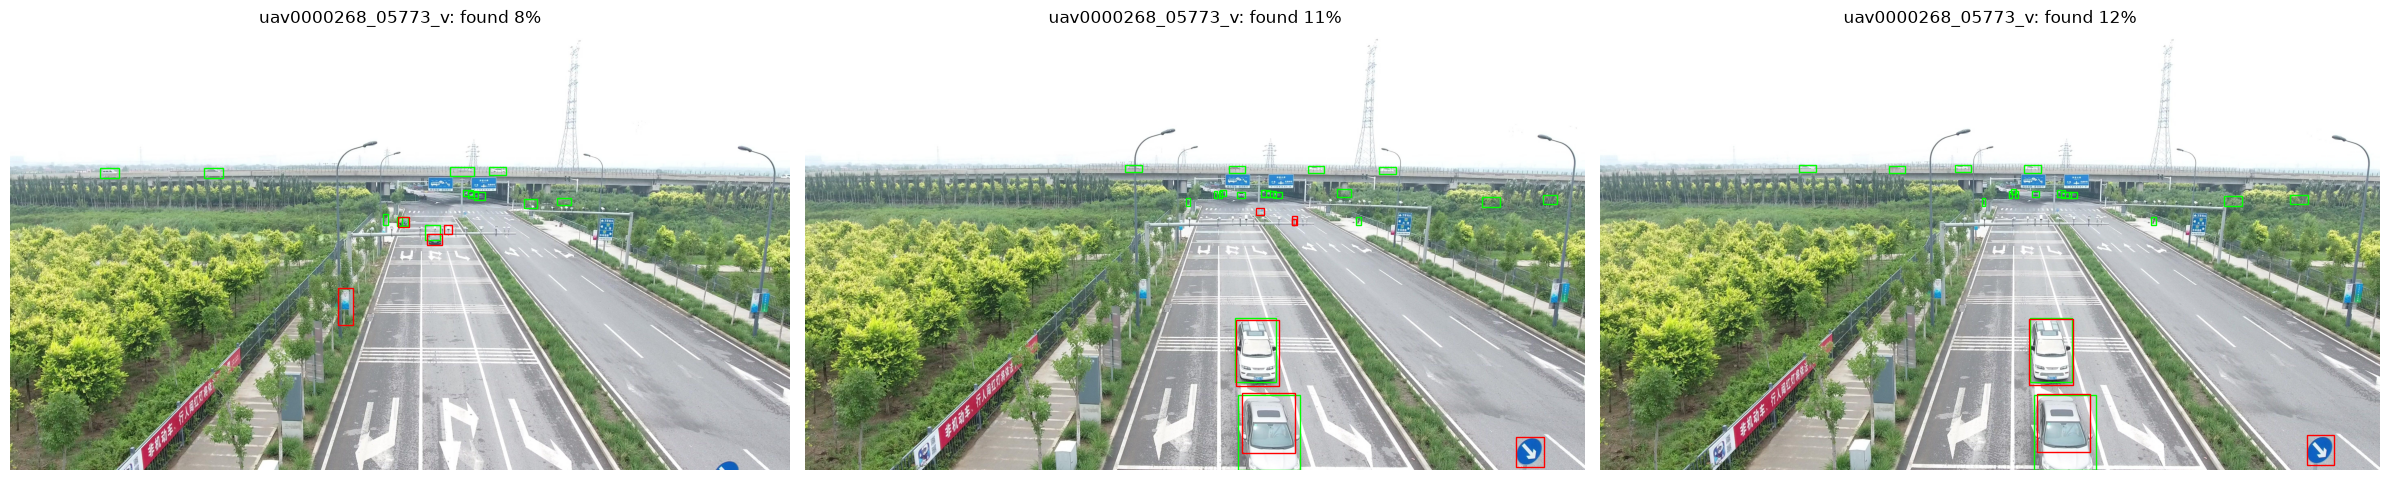

In [19]:
table = pd.DataFrame(results).sort_values("mAP")
best = table.iloc[-1]["experiment"]
val_boxes = load_split("val")[1]

recalls = []
for prediction, row in zip(predictions[best], val_frames.itertuples()):
    frame_boxes = val_boxes[val_boxes["image_id"] == row.image_id]
    recalls.append(frame_recall(prediction, frame_boxes))
worst = np.argsort(recalls)[:3]

fig, ax = plt.subplots(1, 3, figsize=(24, 6))
for a, i in zip(ax, worst):
    row = val_frames.iloc[i]
    frame_boxes = val_boxes[val_boxes["image_id"] == row["image_id"]]
    show_boxes(a, row["path"], frame_boxes, predictions[best][i], title=f"{row['video']}: found {recalls[i]:.0%}")
plt.tight_layout()
plt.savefig(f"{IMAGES}/03_failure_cases.png", dpi=110)
plt.show()

## Conclusions

| experiment | mAP | AP50 | AP_small | AP_medium | AP_large | ms/img |
|---|---|---|---|---|---|---|
| baseline | **0.0953** | **0.2232** | 0.0417 | 0.0754 | **0.2266** | **212.8** |
| small anchors | 0.0950 | 0.2204 | 0.0419 | **0.0809** | 0.2170 | 218.1 |
| small anchors + more proposals | 0.0915 | 0.2167 | **0.0437** | 0.0789 | 0.2195 | 297.9 |

* The differences are very small (less than 0.004 mAP). With 3 epochs and 146 val frames this is close to noise.
* **Small anchors** help a little with small and medium objects, but large objects get worse. The total mAP stays the same.
* **More proposals** give the best AP_small, but the model is 40 % slower (298 vs 213 ms per image) and mAP is lower.

**What each stage gives**
* **RPN (stage 1)** finds places where an object can be. It cuts thousands of anchors down to about 1000-2000 proposals. If the RPN misses an object, stage 2 can never find it.
* **Stage 2** looks at every proposal again. It says the class and makes the box more exact. This is why Faster R-CNN has good boxes on large objects (AP_large 0.23).

**Failure cases** (all 3 frames are from clip uav0000268_05773_v, the model found only 8-11 % of the objects)
1. **Very small objects far away.** Most cars are near the horizon and on the bridge. At 640 px they are only a few pixels, so the model misses them.
2. **Many small objects in a line.** On the bridge the cars stand close to each other. The proposals overlap and NMS removes some real objects.
3. **False positives on road signs.** The blue road sign (bottom right) gets a red box. A sign has a box shape and strong colours, like a small car from above.

All 3 failure frames come from one clip: the camera is high and looks far, so this clip has many tiny objects. A bigger input size or tiles should help here (notebook 07).